In [2]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go


In [3]:
import os

print("Current folder:", os.getcwd())
print("Files available:", os.listdir())

Current folder: C:\Users\chund\Documents\dataviz-exercises-surya\week02
Files available: ['.ipynb_checkpoints', 'lecture02_exercise.ipynb']


In [4]:
df = pd.read_csv(
    r"C:\Users\chund\Documents\data-viz-class-material-w2026\data\world_happiness_2023.csv"
)

df.columns = [
    'Country', 'Region', 'Happiness_Score', 'GDP',
    'Social_Support', 'Life_Expectancy', 'Freedom',
    'Generosity', 'Corruption'
]

print(f"Dataset: {len(df)} countries, {len(df.columns)} columns")
df.head()

Dataset: 63 countries, 9 columns


,Country,Region,Happiness_Score,GDP,Social_Support,Life_Expectancy,Freedom,Generosity,Corruption
0,Finland,Western Europe,7.804,10.775,0.954,71.9,0.949,0.142,0.179
1,Denmark,Western Europe,7.586,10.933,0.954,72.7,0.931,0.168,0.234
2,Iceland,Western Europe,7.525,10.878,0.983,72.5,0.961,0.260,0.150
3,Israel,Middle East and North Africa,7.473,10.527,0.916,72.4,0.903,0.149,0.826
4,Netherlands,Western Europe,7.464,11.015,0.939,72.4,0.879,0.240,0.296


In [5]:
print("Regions in dataset:")
print(df['Region'].value_counts())

print("\nScore range:")
print(df['Happiness_Score'].min(), "-", df['Happiness_Score'].max())

print("\nBottom 10 countries:")
print(
    df.nsmallest(10, 'Happiness_Score')[
        ['Country', 'Region', 'Happiness_Score']
    ]
)

Regions in dataset:
Region
Western Europe                  15
Latin America and Caribbean     13
Central and Eastern Europe       7
Sub-Saharan Africa               7
Middle East and North Africa     6
North America and ANZ            4
Southeast Asia                   4
South Asia                       4
East Asia                        3
Name: count, dtype: int64

Score range:
1.859 - 7.804

Bottom 10 countries:
        Country                        Region  Happiness_Score
60  Afghanistan                    South Asia            1.859
61      Lebanon  Middle East and North Africa            2.392
62     Zimbabwe            Sub-Saharan Africa            2.995
52     Ethiopia            Sub-Saharan Africa            3.564
53     Tanzania            Sub-Saharan Africa            3.698
48   Bangladesh                    South Asia            3.892
47        India                    South Asia            4.036
50        Kenya            Sub-Saharan Africa            4.112
54       Uganda

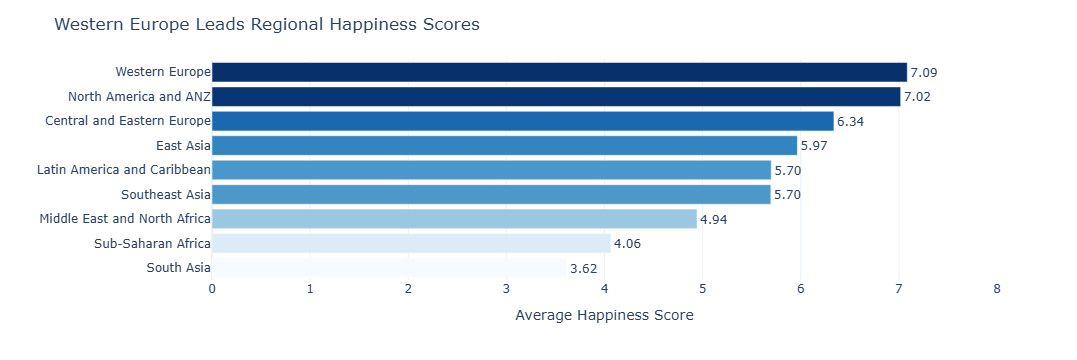

In [6]:
region_avg = (
    df.groupby('Region')['Happiness_Score']
    .mean()
    .reset_index()
    .sort_values('Happiness_Score')
)

fig = px.bar(
    region_avg,
    x='Happiness_Score',
    y='Region',
    orientation='h',
    text='Happiness_Score',
    color='Happiness_Score',
    color_continuous_scale='Blues'
)

fig.update_traces(
    texttemplate='%{text:.2f}',
    textposition='outside'
)

fig.update_layout(
    title='Western Europe Leads Regional Happiness Scores',
    xaxis_title='Average Happiness Score',
    yaxis_title='',
    template='plotly_white',
    coloraxis_showscale=False
)

fig.update_xaxes(range=[0, 8])

fig.show()

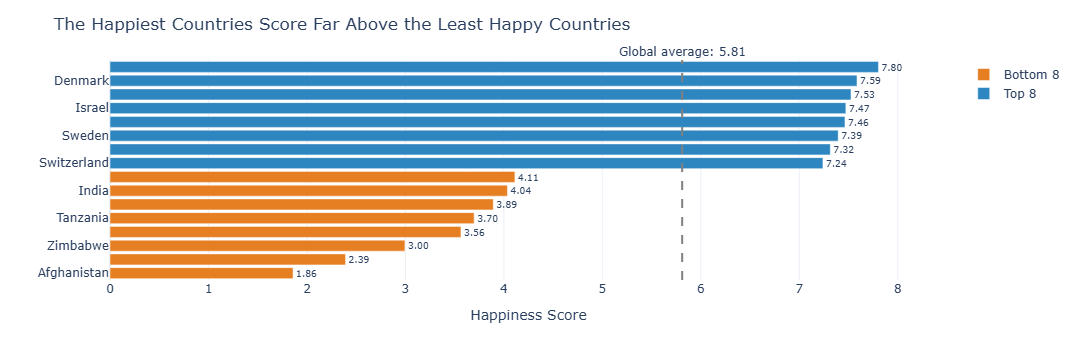

In [7]:
top8 = df.nlargest(8, 'Happiness_Score').copy()
top8['Group'] = 'Top 8'

bottom8 = df.nsmallest(8, 'Happiness_Score').copy()
bottom8['Group'] = 'Bottom 8'

combined = pd.concat([bottom8, top8]).sort_values('Happiness_Score')
global_avg = df['Happiness_Score'].mean()

fig = px.bar(
    combined,
    x='Happiness_Score',
    y='Country',
    orientation='h',
    color='Group',
    text='Happiness_Score',
    color_discrete_map={
        'Top 8': '#2E86C1',
        'Bottom 8': '#E67E22'
    }
)

fig.update_traces(
    texttemplate='%{text:.2f}',
    textposition='outside'
)

fig.add_vline(
    x=global_avg,
    line_dash='dash',
    line_color='gray',
    annotation_text=f'Global average: {global_avg:.2f}',
    annotation_position='top'
)

fig.update_layout(
    title='The Happiest Countries Score Far Above the Least Happy Countries',
    xaxis_title='Happiness Score',
    yaxis_title='',
    template='plotly_white',
    legend_title=''
)

fig.update_xaxes(range=[0, 8.5])

fig.show()